# Ek 6: Govde Merkezli Yari-Toraks Ayrimi ve Yeni Sekiller

Yeniden egitim yoktur, T4 veya L4 uzerinde yaklasik 15-25 dakika surer.

1. **Yari-toraks ayrimi:** Makalede kesit goruntunun dikey orta hattindan ikiye ayrildi. Hasta goruntunun ortasinda degilse bu
   ayrim yaniltabilir. Burada ayrim govde maskesinin agirlik merkezinden yapilir ve bes yapilandirmada iki yontem karsilastirilir.
2. **Sekil 4 (yeni):** SAM2 birlesiminin maskeye sizinti ekledigi test kesiti **onceden tanimli kuralla** secilir:
   model Dice >= 0,8 olan kesitler icinde birlesimle en cok Dice kaybeden kesit.
3. **Sekil 6 (yeni stil):** ek1'de kurallarla secilen basarisiz kesitler ayni sekilde, serif yazi ile yeniden cizilir.

Calistirma: GPU secin ve **Tumunu calistir** deyin. Ciktilar Drive'da `pnx_ek_analizler` klasorune yazilir:
`TABLO_ek6_yaritoraks.csv`, `Figure4_sam2_leakage.png/.pdf`, `Figure_failure_examples.png/.pdf`.

In [1]:
!pip install -q segmentation_models_pytorch==0.5.0 opencv-python-headless pillow scipy matplotlib pandas
!apt-get -qq install -y fonts-liberation > /dev/null
!rm -rf /content/sam2
!git clone -q https://github.com/facebookresearch/sam2.git /content/sam2
%cd /content/sam2
!SAM2_BUILD_CUDA=0 pip install -q -e .
%cd /content
!wget -q -O /content/sam2/checkpoints/sam2.1_hiera_small.pt https://dl.fbaipublicfiles.com/segment_anything_2/092824/sam2.1_hiera_small.pt

/content/sam2
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Building editable for SAM-2 (pyproject.toml) ... done
/content


### Ortak yardimci modul
Asagidaki hucre `pnx_ortak.py` dosyasini Colab diskine yazar. Degistirmeniz gerekmez.

In [2]:
%%writefile /content/pnx_ortak.py
# -*- coding: utf-8 -*-
"""
pnx_ortak.py - Pnomotoraks BT analizi icin ortak yardimci modul.

Veri hazirlama, hasta bazli bolme, U-Net cikarimi (kayan pencere ve tam cozunurluk), SAM2 goruntu ve
video modu, birlestirme kurali, guvenilirlik katsayisi ve metrik fonksiyonlarini icerir.
Sabit tohumla (SEED=42) hasta bazli egitim/dogrulama/test bolmesi uretilir.

Colab'da kullanim:
    import sys; sys.path.insert(0, '/content')
    import pnx_ortak as po
    po.init_unet(); po.init_sam2_image()
"""
import os, glob, random, time
import numpy as np
import cv2
import torch
from PIL import Image
from scipy import ndimage

# ---------------------------------------------------------------------------
# Yapilandirma
# ---------------------------------------------------------------------------
RAW_DIR = '/content/drive/MyDrive/CT_goruntuler_anon'
DRIVE_BACKUP_DIR = '/content/drive/MyDrive/pnx_artifacts'
UNET_WEIGHT_PATH = f'{DRIVE_BACKUP_DIR}/pnomotoraks_unet.pth'

SAM2_REPO_DIR = '/content/sam2'
SAM2_CHECKPOINT = '/content/sam2/checkpoints/sam2.1_hiera_small.pt'
SAM2_CONFIG = 'configs/sam2.1/sam2.1_hiera_s.yaml'

IMAGE_SIZE = 224
PATCH_STRIDE = 224
SEED = 42
PNEUMOTHORAX_LABEL = 1
LUNG_LABEL = 2
TRAIN_RATIO = 0.65
VAL_RATIO = 0.10

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

unet_model = None
sam2_image_predictor = None
_sam2_base_model = None

# Segmentasyon modeli ve son isleme ayarlari. Varsayilan: 224x224 parca U-Net, esik 0.5, 80 pikselden kucuk
# bilesenleri at, yalnizca en buyuk bileseni tut. Dogrulamada secilen ayarlar load_segmenter_config() ile yuklenir.
SEG = {
    'kind': 'unet_patch',     # 'unet_patch' (parca U-Net) | 'guclu' (tam cozunurluklu ResNet34 U-Net)
    'threshold': 0.5,
    'min_area': 80,
    'keep': 'largest',        # 'largest' | 'all' | 'top2'
    'tta': False,             # yatay cevirme ile test-zamani artirma
    'lung_filter': False,     # yalnizca 'guclu': akciger olasiligi yuksek bolgeye dusen pnomotoraks bilesenlerini at
}
strong_model = None
LAST_LUNG_PROB = None


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


# ---------------------------------------------------------------------------
# Veri: hasta indeksi ve hasta bazli bolme
# ---------------------------------------------------------------------------
def _slice_sort_key(path):
    stem = os.path.splitext(os.path.basename(path))[0]
    return (0, int(stem)) if stem.isdigit() else (1, stem)


def find_pairs_for_patient(patient_dir, numeric_order=False):
    # numeric_order=False: alfabetik siralama.
    # numeric_order=True : kesitleri sayisal sirada dondurur (video/sekans isleme icin;
    #                      '10.jpg' '2.jpg'den once gelmesin).
    pairs = []
    jpg_files = sorted(glob.glob(os.path.join(patient_dir, '*.jpg')))
    if numeric_order:
        jpg_files = sorted(jpg_files, key=_slice_sort_key)
    for jpg_path in jpg_files:
        stem = os.path.splitext(os.path.basename(jpg_path))[0]
        png_path = os.path.join(patient_dir, stem + '.png')
        if os.path.exists(png_path):
            pairs.append((jpg_path, png_path))
    return pairs


def build_patient_split(raw_dir=RAW_DIR, seed=SEED, numeric_order=True):
    """Sabit tohumla hasta bazli bolme uretir.

    Donus: patient_index {pid: [(jpg, png), ...]}, split_of_patient {pid: 'train'|'val'|'test'}
    """
    patient_dirs = sorted([d for d in glob.glob(os.path.join(raw_dir, '*')) if os.path.isdir(d)])
    patient_index = {}
    for pdir in patient_dirs:
        pid = os.path.basename(pdir)
        pairs = find_pairs_for_patient(pdir, numeric_order=numeric_order)
        if len(pairs) > 0:
            patient_index[pid] = pairs

    # Uyari: yalnizca kucuk harfli .jpg/.png ciftleri kullanilir. .jpeg veya .PNG gibi uzantilar Linux/Colab'da
    # eslesmez ve atlanir. Atlanan dosyalar burada listelenir.
    atlanan = [os.path.relpath(f, raw_dir) for d in patient_dirs for f in glob.glob(os.path.join(d, '*'))
               if not f.endswith(('.jpg', '.png'))]
    if atlanan:
        print(f'UYARI: standart disi uzantili {len(atlanan)} dosya kullanilmadi (ornek: {atlanan[:3]})')

    patient_ids = sorted(patient_index.keys())
    rng = random.Random(seed)
    rng.shuffle(patient_ids)
    n = len(patient_ids)
    n_train = int(round(n * TRAIN_RATIO))
    n_val = int(round(n * VAL_RATIO))
    split_of_patient = {}
    for pid in patient_ids[:n_train]:
        split_of_patient[pid] = 'train'
    for pid in patient_ids[n_train:n_train + n_val]:
        split_of_patient[pid] = 'val'
    for pid in patient_ids[n_train + n_val:]:
        split_of_patient[pid] = 'test'
    return patient_index, split_of_patient


def load_image_rgb(image_path):
    image = cv2.imread(image_path, cv2.IMREAD_COLOR)
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


def load_label_map(mask_path):
    m = np.array(Image.open(mask_path))
    if m.ndim == 3:
        m = m[..., 0]
    return m


def load_binary_mask(mask_path, label=PNEUMOTHORAX_LABEL):
    return (load_label_map(mask_path) == label).astype(np.uint8)


# ---------------------------------------------------------------------------
# Morfolojik yardimcilar ve rapor yardimcilari
# ---------------------------------------------------------------------------
def clean_mask(mask, min_area=80):
    mask = (mask > 0).astype(np.uint8)
    labeled, num = ndimage.label(mask)
    out = np.zeros_like(mask, dtype=np.uint8)
    for i in range(1, num + 1):
        region = (labeled == i)
        if region.sum() >= min_area:
            out[region] = 1
    return out


def largest_component(mask):
    labeled, num = ndimage.label(mask)
    if num == 0:
        return mask.astype(np.uint8)
    sizes = ndimage.sum(mask, labeled, range(1, num + 1))
    return (labeled == (int(np.argmax(sizes)) + 1)).astype(np.uint8)


def keep_components(mask, keep=None):
    keep = SEG['keep'] if keep is None else keep
    mask = (mask > 0).astype(np.uint8)
    if keep == 'largest':
        return largest_component(mask)
    if keep == 'top2':
        labeled, num = ndimage.label(mask)
        if num <= 2:
            return mask
        sizes = ndimage.sum(mask, labeled, range(1, num + 1))
        top = np.argsort(sizes)[::-1][:2] + 1
        return np.isin(labeled, top).astype(np.uint8)
    return mask


def postprocess_mask(mask, min_area=None, keep=None):
    """Ikili maskeye SEG ayarlarina gore kucuk bilesen temizligi + bilesen politikasi uygular."""
    return keep_components(clean_mask(mask, SEG['min_area'] if min_area is None else min_area), keep)


def area_ratio(mask):
    return float(mask.sum() / mask.size)


def estimate_side(mask, radiological_convention=True):
    """Pnomotoraksin tarafini tahmin eder.

    DIKKAT: Aksiyel BT goruntuleri radyolojik konvansiyonda gosterilir; goruntunun
    SOL yarisi hastanin SAG tarafidir. Varsayilan olarak radyolojik konvansiyon kullanilir.
    Goruntu cercevesine gore taraf gerekiyorsa radiological_convention=False verin.
    """
    if mask.sum() == 0:
        return 'belirgin degil'
    h, w = mask.shape
    img_left = mask[:, :w // 2].sum()
    img_right = mask[:, w // 2:].sum()
    if radiological_convention:
        side_of_img_left, side_of_img_right = 'sag', 'sol'
    else:
        side_of_img_left, side_of_img_right = 'sol', 'sag'
    if img_left > img_right * 1.2:
        return side_of_img_left
    elif img_right > img_left * 1.2:
        return side_of_img_right
    return 'bilateral'


def estimate_extent(mask):
    r = area_ratio(mask)
    if r < 0.005:
        return 'cok kucuk'
    elif r < 0.02:
        return 'kucuk'
    elif r < 0.06:
        return 'orta'
    return 'genis'


def make_overlay(image_np, mask, color=(255, 0, 0), alpha=0.35):
    overlay = image_np.copy()
    m = mask.astype(bool)
    col = np.array(color, dtype=np.float32)
    overlay[m] = ((1 - alpha) * overlay[m] + alpha * col).astype(np.uint8)
    return overlay


def mask_iou(mask_a, mask_b):
    inter = np.logical_and(mask_a > 0, mask_b > 0).sum()
    union = np.logical_or(mask_a > 0, mask_b > 0).sum()
    return 0.0 if union == 0 else float(inter) / float(union)


def mask_box(mask, margin=10):
    h, w = mask.shape
    ys, xs = np.where(mask > 0)
    return np.array([max(0, xs.min() - margin), max(0, ys.min() - margin),
                     min(w - 1, xs.max() + margin), min(h - 1, ys.max() + margin)])


# ---------------------------------------------------------------------------
# Metrikler
# ---------------------------------------------------------------------------
def segmentation_metrics(pred_mask, gt_mask, eps=1e-6):
    p = pred_mask.flatten().astype(np.uint8)
    g = gt_mask.flatten().astype(np.uint8)
    tp = int(np.sum((p == 1) & (g == 1)))
    tn = int(np.sum((p == 0) & (g == 0)))
    fp = int(np.sum((p == 1) & (g == 0)))
    fn = int(np.sum((p == 0) & (g == 1)))
    sens = (tp + eps) / (tp + fn + eps)
    prec = (tp + eps) / (tp + fp + eps)
    return {
        'dice': (2 * tp + eps) / (2 * tp + fp + fn + eps),
        'iou': (tp + eps) / (tp + fp + fn + eps),
        'accuracy': (tp + tn + eps) / (tp + tn + fp + fn + eps),
        'sensitivity': sens,
        'specificity': (tn + eps) / (tn + fp + eps),
        'precision': prec,
        'f1': (2 * prec * sens + eps) / (prec + sens + eps),
    }


def hd95_pixels(pred_mask, gt_mask):
    pred_mask = (pred_mask > 0).astype(np.uint8)
    gt_mask = (gt_mask > 0).astype(np.uint8)
    if pred_mask.sum() == 0 or gt_mask.sum() == 0:
        return float('nan')
    pb = pred_mask - ndimage.binary_erosion(pred_mask).astype(np.uint8)
    gb = gt_mask - ndimage.binary_erosion(gt_mask).astype(np.uint8)
    if pb.sum() == 0 or gb.sum() == 0:
        return float('nan')
    gt_dt = ndimage.distance_transform_edt(1 - gb)
    pr_dt = ndimage.distance_transform_edt(1 - pb)
    return float(max(np.percentile(gt_dt[pb > 0], 95), np.percentile(pr_dt[gb > 0], 95)))


def hemithorax_counts(pred_mask, gt_mask, min_pixels=50):
    """Yari-toraks (goruntunun sol/sag yarisi) duzeyinde tespit sayimlari.

    Veri setindeki kesitlerin neredeyse tamami pnomotoraks pozitiftir (851/852), bu yuzden kesit
    duzeyinde ozgulluk olculemez. Pnomotoraks cogunlukla tek tarafli oldugundan, referans maskede pnomotoraks
    olmayan karsi yari-toraks dogal bir negatif ornektir; burada tahmin edilen maske varsa yanlis pozitiftir.
    Donus: {'tp','fn','tn','fp'} (iki yari uzerinden toplam)."""
    w = gt_mask.shape[1]
    c = {'tp': 0, 'fn': 0, 'tn': 0, 'fp': 0}
    for sl in (slice(0, w // 2), slice(w // 2, w)):
        g = gt_mask[:, sl].sum() >= min_pixels
        p = pred_mask[:, sl].sum() >= min_pixels
        c['tp' if g and p else 'fn' if g else 'fp' if p else 'tn'] += 1
    return c


def dice_3d(pred_vol, gt_vol, eps=1e-6):
    p = pred_vol > 0
    g = gt_vol > 0
    inter = np.logical_and(p, g).sum()
    return float((2 * inter + eps) / (p.sum() + g.sum() + eps))


def bootstrap_ci(values, n_boot=2000, alpha=0.05, seed=SEED):
    values = np.asarray([v for v in values if not np.isnan(v)])
    if len(values) == 0:
        return float('nan'), float('nan'), float('nan')
    rng = np.random.default_rng(seed)
    means = [rng.choice(values, len(values), replace=True).mean() for _ in range(n_boot)]
    return float(values.mean()), float(np.percentile(means, 100 * alpha / 2)), float(np.percentile(means, 100 * (1 - alpha / 2)))


# ---------------------------------------------------------------------------
# U-Net
# ---------------------------------------------------------------------------
def init_unet(weight_path=UNET_WEIGHT_PATH):
    global unet_model
    import segmentation_models_pytorch as smp
    unet_model = smp.Unet(encoder_name='mobilenet_v2', encoder_weights=None,
                          in_channels=3, classes=1, activation=None).to(DEVICE)
    unet_model.load_state_dict(torch.load(weight_path, map_location=DEVICE))
    unet_model.eval()
    print('U-Net yuklendi:', weight_path)
    return unet_model


_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)


def _to_tensor(patch_rgb):
    x = (patch_rgb.astype(np.float32) / 255.0 - _MEAN) / _STD
    return torch.from_numpy(x.transpose(2, 0, 1)).unsqueeze(0)


def unet_prob_map(image_np, tta=None):
    """Aktif segmentasyon modeliyle tam goruntu pnomotoraks olasilik haritasi (HxW, 0-1).
    SEG['kind'] == 'guclu' ise tam cozunurluk modeli, aksi halde 224x224 parca U-Net kullanilir."""
    global LAST_LUNG_PROB
    tta = SEG['tta'] if tta is None else tta
    fn = _strong_prob if SEG['kind'] == 'guclu' else _patch_unet_prob_map
    p, lung = fn(image_np)
    if tta:
        p2, lung2 = fn(np.ascontiguousarray(image_np[:, ::-1]))
        p = (p + p2[:, ::-1]) / 2
        if lung is not None:
            lung = (lung + lung2[:, ::-1]) / 2
    LAST_LUNG_PROB = lung
    return p


@torch.no_grad()
def _strong_prob(image_np):
    h, w = image_np.shape[:2]
    H, W = int(np.ceil(h / 32) * 32), int(np.ceil(w / 32) * 32)
    img = cv2.copyMakeBorder(image_np, 0, H - h, 0, W - w, cv2.BORDER_CONSTANT, value=0)
    x = _to_tensor(img).to(DEVICE)
    with torch.autocast('cuda', enabled=(DEVICE == 'cuda')):
        out = torch.sigmoid(strong_model(x).float())[0].cpu().numpy()
    lung = out[1, :h, :w] if out.shape[0] > 1 else None
    return out[0, :h, :w], lung


def init_strong_model(weight_path, arch='Unet', encoder='resnet34', classes=2):
    global strong_model
    import segmentation_models_pytorch as smp
    strong_model = getattr(smp, arch)(encoder_name=encoder, encoder_weights=None, in_channels=3, classes=classes).to(DEVICE)
    strong_model.load_state_dict(torch.load(weight_path, map_location=DEVICE))
    strong_model.eval()
    SEG['kind'] = 'guclu'
    print('Guclu segmentasyon modeli yuklendi:', weight_path, arch, encoder)
    return strong_model


def load_segmenter_config(path):
    """Segmenter ayar dosyasini (model agirligi + dogrulamada secilen son isleme) yukler."""
    import json as _json
    cfg = _json.load(open(path))
    if cfg.get('kind') == 'guclu':
        init_strong_model(cfg['weight_path'], cfg.get('arch', 'Unet'), cfg.get('encoder', 'resnet34'), cfg.get('classes', 2))
    elif unet_model is None:
        init_unet()
    for k in ('kind', 'threshold', 'min_area', 'keep', 'tta', 'lung_filter'):
        if k in cfg:
            SEG[k] = cfg[k]
    print('Segmenter ayari:', SEG)
    return cfg


@torch.no_grad()
def _patch_unet_prob_map(image_np, patch_size=IMAGE_SIZE, stride=PATCH_STRIDE, batch_size=16):
    """Kaydirmali pencere ile tam goruntu olasilik haritasi (HxW, 0-1) (parca U-Net)."""
    h, w = image_np.shape[:2]
    ys = [0] if h <= patch_size else sorted(set(list(range(0, h - patch_size, stride)) + [h - patch_size]))
    xs = [0] if w <= patch_size else sorted(set(list(range(0, w - patch_size, stride)) + [w - patch_size]))
    prob_map = np.zeros((h, w), dtype=np.float32)
    count_map = np.zeros((h, w), dtype=np.float32)
    coords, tensors = [], []
    for y in ys:
        for x in xs:
            patch = image_np[y:y + patch_size, x:x + patch_size]
            ph, pw = patch.shape[:2]
            if ph < patch_size or pw < patch_size:
                patch = cv2.copyMakeBorder(patch, 0, patch_size - ph, 0, patch_size - pw, cv2.BORDER_CONSTANT, value=0)
            coords.append((y, x, ph, pw))
            tensors.append(_to_tensor(patch))
    for i in range(0, len(tensors), batch_size):
        batch = torch.cat(tensors[i:i + batch_size]).to(DEVICE)
        probs = torch.sigmoid(unet_model(batch))[:, 0].cpu().numpy()
        for (y, x, ph, pw), pr in zip(coords[i:i + batch_size], probs):
            prob_map[y:y + ph, x:x + pw] += pr[:ph, :pw]
            count_map[y:y + ph, x:x + pw] += 1.0
    count_map[count_map == 0] = 1.0
    return prob_map / count_map, None


def mask_from_prob(prob, lung_prob=None, threshold=None, min_area=None, keep=None, lung_filter=None):
    threshold = SEG['threshold'] if threshold is None else threshold
    lung_filter = SEG['lung_filter'] if lung_filter is None else lung_filter
    m = clean_mask((prob > threshold).astype(np.uint8), SEG['min_area'] if min_area is None else min_area)
    if lung_filter and lung_prob is not None and m.sum() > 0:
        # Pnomotoraks akciger parankiminin DISINDA (plevral bosluk) yer alir; akciger olasiligi
        # yuksek bolgeyle cogunlukla ortusen bilesenler yanlis pozitif kabul edilir.
        lab, n = ndimage.label(m)
        for j in range(1, n + 1):
            reg = lab == j
            if lung_prob[reg].mean() > 0.5:
                m[reg] = 0
    return keep_components(m, keep)


def unet_predict(image_np, threshold=None):
    """Cikti: (maske, guven, olasilik haritasi). Son isleme SEG ayarlarina gore yapilir."""
    prob = unet_prob_map(image_np)
    mask = mask_from_prob(prob, LAST_LUNG_PROB, threshold=threshold)
    return mask, float(prob.max()), prob


# ---------------------------------------------------------------------------
# SAM2 (goruntu modu)
# ---------------------------------------------------------------------------
def _sam2_import():
    import sys
    if SAM2_REPO_DIR not in sys.path:
        sys.path.insert(0, SAM2_REPO_DIR)


def init_sam2_image():
    global sam2_image_predictor, _sam2_base_model
    _sam2_import()
    from sam2.build_sam import build_sam2
    from sam2.sam2_image_predictor import SAM2ImagePredictor
    _sam2_base_model = build_sam2(config_file=SAM2_CONFIG, ckpt_path=SAM2_CHECKPOINT, device=DEVICE)
    sam2_image_predictor = SAM2ImagePredictor(_sam2_base_model)
    print('SAM2 (goruntu modu) hazir.')
    return sam2_image_predictor


def init_sam2_video(offload_video_to_cpu=False):
    _sam2_import()
    from sam2.build_sam import build_sam2_video_predictor
    vp = build_sam2_video_predictor(SAM2_CONFIG, SAM2_CHECKPOINT, device=DEVICE)
    print('SAM2 (video modu) hazir.')
    return vp


@torch.no_grad()
def sam2_set_image(image_np):
    sam2_image_predictor.set_image(image_np)


@torch.no_grad()
def sam2_predict(image_np, unet_mask, prompt_type='box', box_margin=10, multimask_select='score',
                 image_already_set=False):
    """SAM2 goruntu modu tahmini.

    prompt_type: 'box' | 'point' | 'box+point'
    multimask_select: 'score' (en yuksek SAM skoru) |
                      'agreement' (U-Net maskesiyle en yuksek IoU'lu aday)
    SEG['keep'] != 'largest' ise U-Net maskesinin her bagli bileseni (or. iki tarafli pnomotoraks)
    icin ayri istem verilir ve sonuclar birlestirilir.
    """
    if not image_already_set:
        sam2_image_predictor.set_image(image_np)
    if SEG['keep'] != 'largest' and unet_mask.sum() > 0:
        lab, n = ndimage.label(unet_mask > 0)
        if n > 1:
            out, skorlar, alanlar = np.zeros_like(unet_mask, dtype=np.uint8), [], []
            for j in range(1, n + 1):
                comp = (lab == j).astype(np.uint8)
                m, s = _sam2_tek(image_np, comp, prompt_type, box_margin, multimask_select)
                out = np.logical_or(out, m).astype(np.uint8)
                skorlar.append(s); alanlar.append(comp.sum())
            return keep_components(out), float(np.average(skorlar, weights=alanlar))
    return _sam2_tek(image_np, unet_mask, prompt_type, box_margin, multimask_select)


def _sam2_tek(image_np, unet_mask, prompt_type, box_margin, multimask_select):
    h, w = image_np.shape[:2]
    has_mask = unet_mask.sum() > 0
    box = mask_box(unet_mask, box_margin) if has_mask else np.array([int(w * .05), int(h * .05), int(w * .95), int(h * .95)])
    if has_mask:
        ys, xs = np.where(unet_mask > 0)
        # Agirlik merkezi maskenin disina dusebilir (hilal seklindeki pnomotoraks);
        # bu yuzden maske icinde merkeze en yakin piksel kullanilir.
        cy, cx = ys.mean(), xs.mean()
        j = int(np.argmin((ys - cy) ** 2 + (xs - cx) ** 2))
        point = np.array([[int(xs[j]), int(ys[j])]])
    else:
        point = np.array([[w // 2, h // 2]])

    kwargs = dict(multimask_output=True)
    if prompt_type == 'box':
        kwargs.update(point_coords=None, point_labels=None, box=box)
    elif prompt_type == 'point':
        kwargs.update(point_coords=point, point_labels=np.array([1]), box=None)
    else:
        kwargs.update(point_coords=point, point_labels=np.array([1]), box=box)
    masks, scores, _ = sam2_image_predictor.predict(**kwargs)

    # Tek bir bilesen/istem icin SAM2 cikti adayinin en buyuk bileseni alinir.
    cands = [largest_component(clean_mask(m.astype(np.uint8))) for m in masks]
    if multimask_select == 'agreement' and has_mask:
        best = int(np.argmax([mask_iou(c, unet_mask) for c in cands]))
    else:
        best = int(np.argmax(scores))
    return cands[best], float(scores[best])


def combine_masks(unet_mask, sam_mask, min_agreement_iou=0.3):
    # Kural: U-Net negatifse bos, uyum dusukse U-Net maskesine geri dus.
    # Bilesen politikasi SEG['keep'] ile belirlenir (varsayilan 'largest').
    if unet_mask.sum() == 0:
        return np.zeros_like(sam_mask, dtype=np.uint8)
    if mask_iou(unet_mask, sam_mask) < min_agreement_iou:
        return postprocess_mask(unet_mask)
    return postprocess_mask(np.logical_or(unet_mask > 0, sam_mask > 0).astype(np.uint8))


def compute_reliability(unet_conf, sam_conf, final_mask, wU=0.35, wS=0.45, wA=0.20):
    area_term = min(area_ratio(final_mask) / 0.03, 1.0)
    return float(max(0.0, min(1.0, wU * unet_conf + wS * sam_conf + wA * area_term)))


def baseline_pipeline(image_np):
    """Tek gecisli hat: U-Net -> SAM2 kutu istemi -> birlestirme."""
    t0 = time.time()
    unet_mask, unet_conf, prob = unet_predict(image_np)
    sam_mask, sam_conf = sam2_predict(image_np, unet_mask, prompt_type='box', box_margin=10)
    final = combine_masks(unet_mask, sam_mask)
    return {
        'mask': final, 'unet_mask': unet_mask, 'sam_mask': sam_mask,
        'unet_conf': unet_conf, 'sam_conf': sam_conf, 'prob': prob,
        'reliability': compute_reliability(unet_conf, sam_conf, final),
        'time_s': time.time() - t0,
    }


# ---------------------------------------------------------------------------
# Anatomik olabilirlik yardimcilari (dogrulama denetimleri icin)
# ---------------------------------------------------------------------------
def body_mask(image_np, thr=20):
    """Govde (vucut) maskesi: goruntu esiklenir, en buyuk bilesen alinir, delikleri doldurulur.
    Pnomotoraks havasi govde ICINDE, hasta disindaki hava govde DISINDA kalir."""
    gray = cv2.cvtColor(image_np, cv2.COLOR_RGB2GRAY) if image_np.ndim == 3 else image_np
    m = (gray > thr).astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, np.ones((15, 15), np.uint8))
    m = largest_component(m)
    return ndimage.binary_fill_holes(m).astype(np.uint8)


def mean_intensity_in_mask(image_np, mask):
    gray = cv2.cvtColor(image_np, cv2.COLOR_RGB2GRAY) if image_np.ndim == 3 else image_np
    return float(gray[mask > 0].mean()) if mask.sum() > 0 else float('nan')


# ---------------------------------------------------------------------------
# VLM (Qwen2-VL)
# ---------------------------------------------------------------------------
vlm_model = None
vlm_processor = None
VLM_MODEL_ID = 'Qwen/Qwen2-VL-2B-Instruct'


def init_vlm(model_id=VLM_MODEL_ID):
    global vlm_model, vlm_processor, VLM_MODEL_ID
    from transformers import Qwen2VLForConditionalGeneration, AutoProcessor
    VLM_MODEL_ID = model_id
    vlm_model = Qwen2VLForConditionalGeneration.from_pretrained(model_id, torch_dtype=torch.float16, device_map='auto')
    vlm_processor = AutoProcessor.from_pretrained(model_id)
    print('VLM hazir:', model_id)


@torch.no_grad()
def vlm_generate(image_pil, prompt_text, max_new_tokens=400, temperature=0.6, seed=None):
    from qwen_vl_utils import process_vision_info
    if seed is not None:
        torch.manual_seed(seed)
    messages = [{'role': 'user', 'content': [{'type': 'image', 'image': image_pil}, {'type': 'text', 'text': prompt_text}]}]
    chat = vlm_processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    image_inputs, video_inputs = process_vision_info(messages)
    inputs = vlm_processor(text=[chat], images=image_inputs, videos=video_inputs, padding=True, return_tensors='pt').to(DEVICE)
    out = vlm_model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=True,
                             temperature=temperature, top_p=0.9, repetition_penalty=1.3)
    trimmed = [o[len(i):] for i, o in zip(inputs.input_ids, out)]
    return vlm_processor.batch_decode(trimmed, skip_special_tokens=True, clean_up_tokenization_spaces=False)[0].strip()

Writing /content/pnx_ortak.py


In [3]:
import os, sys
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import torch
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager

assert torch.cuda.is_available(), 'GPU yok: Calisma zamani turunu GPU yapip yeniden baslatin'
from google.colab import drive
drive.mount('/content/drive')
sys.path.insert(0, '/content')
import pnx_ortak as po

font_manager._load_fontmanager(try_read_cache=False)
plt.rcParams.update({'font.family': 'serif', 'font.serif': ['Liberation Serif', 'DejaVu Serif'], 'font.size': 10, 'pdf.fonttype': 42})
po.set_seed()
D = '/content/drive/MyDrive'


def bul(*yollar):
    # Ilk calistirmadaki ve yayin surumundeki Drive klasor adlarinin ikisi de denenir
    for y in yollar:
        if os.path.exists(y):
            print('Bulundu:', y)
            return y
    raise FileNotFoundError('Hicbiri bulunamadi, yolu elle girin: ' + ' | '.join(yollar))


AGIRLIK_TEK = bul(f'{D}/pnx_calisma1b/guclu_Unet_resnet34_akcigersiz.pth', f'{D}/pnx_taban/guclu_Unet_resnet34_akcigersiz.pth')
AGIRLIK_COK = bul(f'{D}/pnx_calisma1b/guclu_Unet_resnet34.pth', f'{D}/pnx_taban/guclu_Unet_resnet34.pth')
AGIRLIK_TEMEL = bul(f'{D}/pnomotoraks_v3_artifacts/pnomotoraks_unet.pth', po.UNET_WEIGHT_PATH)
OUT_DIR = f'{D}/pnx_ek_analizler'
SECIM_CSV = bul(f'{OUT_DIR}/ek1_secilen_basarisiz_kesitler.csv')

patient_index, split_of_patient = po.build_patient_split()
TEST = [(pid, os.path.basename(j), j, m) for pid in sorted(p for p, s in split_of_patient.items() if s == 'test') for j, m in patient_index[pid]]
HAVUZ = ThreadPoolExecutor(8)
IMG = list(HAVUZ.map(po.load_image_rgb, [k[2] for k in TEST]))
GT = list(HAVUZ.map(po.load_binary_mask, [k[3] for k in TEST]))
assert len(TEST) == 211, 'Test seti makaledeki bolmeyle uyusmuyor'
GOVDE_X = [float(np.nonzero(po.body_mask(im))[1].mean()) for im in IMG]
kayma = np.abs(np.array(GOVDE_X) - np.array([im.shape[1] / 2 for im in IMG]))
print(f'Govde merkezinin orta hattan uzakligi (piksel): medyan {np.median(kayma):.1f}, en buyuk {kayma.max():.1f}, '
      f'>20 piksel {int((kayma > 20).sum())} kesit')

Mounted at /content/drive
Bulundu: /content/drive/MyDrive/pnx_calisma1b/guclu_Unet_resnet34_akcigersiz.pth
Bulundu: /content/drive/MyDrive/pnx_calisma1b/guclu_Unet_resnet34.pth
Bulundu: /content/drive/MyDrive/pnomotoraks_v3_artifacts/pnomotoraks_unet.pth
Bulundu: /content/drive/MyDrive/pnx_ek_analizler/ek1_secilen_basarisiz_kesitler.csv
UYARI: standart disi uzantili 27 dosya kullanilmadi (ornek: ['1426520/4.PNG', '1637290/5.jpeg', '1757286/2.jpeg'])
Govde merkezinin orta hattan uzakligi (piksel): medyan 5.4, en buyuk 93.7, >20 piksel 46 kesit


## 1. Maskeler: bes yapilandirma (makaledeki ayarlar)

In [4]:
def yt(pred, gt, x, min_pixels=50):
    # Yari-toraks sayimi: x sutunundan ikiye ayrim (pnx_ortak.hemithorax_counts ile ayni kural)
    x = int(round(x)); c = {'tp': 0, 'fn': 0, 'tn': 0, 'fp': 0}
    for sl in (slice(0, x), slice(x, gt.shape[1])):
        g = gt[:, sl].sum() >= min_pixels; p = pred[:, sl].sum() >= min_pixels
        c['tp' if g and p else 'fn' if g else 'fp' if p else 'tn'] += 1
    return c


MASKE = {}
po.init_unet(AGIRLIK_TEMEL)
po.SEG.update(kind='unet_patch', threshold=0.5, min_area=80, keep='largest', tta=False, lung_filter=False)
MASKE['Baseline U-Net, default post-processing'] = [po.unet_predict(im)[0] for im in IMG]
po.SEG.update(threshold=0.3, min_area=20, keep='all', tta=True)
MASKE['Baseline U-Net + post-processing + TTA'] = [po.unet_predict(im)[0] for im in IMG]
po.init_strong_model(AGIRLIK_COK, 'Unet', 'resnet34', classes=2)
po.SEG.update(kind='guclu', threshold=0.3, min_area=20, keep='all', tta=True, lung_filter=False)
MASKE['Strong model, multi-task + TTA'] = [po.unet_predict(im)[0] for im in IMG]
po.init_strong_model(AGIRLIK_TEK, 'Unet', 'resnet34', classes=1)
po.SEG.update(kind='guclu', threshold=0.3, min_area=20, keep='top2', tta=True, lung_filter=False)
po.init_sam2_image()
tek, bir = [], []
for im in IMG:
    r = po.baseline_pipeline(im)
    tek.append(r['unet_mask']); bir.append(r['mask'])
MASKE['Strong model, single-task + TTA (model alone)'] = tek
MASKE['Single-task + SAM2 fusion (single pass)'] = bir
BEKLENEN = {'Baseline U-Net, default post-processing': (0.650, 0.976), 'Baseline U-Net + post-processing + TTA': (0.705, 0.805),
            'Strong model, multi-task + TTA': (0.783, 0.872), 'Strong model, single-task + TTA (model alone)': (0.797, 0.945),
            'Single-task + SAM2 fusion (single pass)': (0.725, 0.921)}
satir = []
for ad, ms in MASKE.items():
    dice = np.mean([po.segmentation_metrics(m, g)['dice'] for m, g in zip(ms, GT)])
    for yontem, xs in (('orta hat', [im.shape[1] / 2 for im in IMG]), ('govde merkezi', GOVDE_X)):
        t = {'tp': 0, 'fn': 0, 'tn': 0, 'fp': 0}
        for m, g, x in zip(ms, GT, xs):
            for k, v in yt(m, g, x).items():
                t[k] += v
        satir.append({'yapilandirma': ad, 'ayrim': yontem, 'Dice': dice, **t, 'YT duyarlilik': t['tp'] / (t['tp'] + t['fn']),
                      'YT ozgulluk': t['tn'] / (t['tn'] + t['fp']), 'makale Dice': BEKLENEN[ad][0], 'makale YT ozgulluk': BEKLENEN[ad][1]})
YT = pd.DataFrame(satir)
YT.to_csv(f'{OUT_DIR}/TABLO_ek6_yaritoraks.csv', index=False)
display(YT.round(4))
print('Orta hat satirlari makaledeki Dice ve YT ozgulluk degerlerini vermelidir (0,01 icinde).')

U-Net yuklendi: /content/drive/MyDrive/pnomotoraks_v3_artifacts/pnomotoraks_unet.pth
Guclu segmentasyon modeli yuklendi: /content/drive/MyDrive/pnx_calisma1b/guclu_Unet_resnet34.pth Unet resnet34
Guclu segmentasyon modeli yuklendi: /content/drive/MyDrive/pnx_calisma1b/guclu_Unet_resnet34_akcigersiz.pth Unet resnet34


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


SAM2 (goruntu modu) hazir.


,yapilandirma,ayrim,Dice,tp,fn,tn,fp,YT duyarlilik,YT ozgulluk,makale Dice,makale YT ozgulluk
0,"Baseline U-Net, default post-processing",orta hat,0.6499,213,45,160,4,0.8256,0.9756,0.650,0.976
1,"Baseline U-Net, default post-processing",govde merkezi,0.6499,219,45,154,4,0.8295,0.9747,0.650,0.976
2,Baseline U-Net + post-processing + TTA,orta hat,0.7051,232,26,132,32,0.8992,0.8049,0.705,0.805
3,Baseline U-Net + post-processing + TTA,govde merkezi,0.7051,237,27,131,27,0.8977,0.8291,0.705,0.805
4,"Strong model, multi-task + TTA",orta hat,0.7833,239,19,143,21,0.9264,0.8720,0.783,0.872
5,"Strong model, multi-task + TTA",govde merkezi,0.7833,247,17,140,18,0.9356,0.8861,0.783,0.872
6,"Strong model, single-task + TTA (model alone)",orta hat,0.7974,236,22,155,9,0.9147,0.9451,0.797,0.945
7,"Strong model, single-task + TTA (model alone)",govde merkezi,0.7974,244,20,148,10,0.9242,0.9367,0.797,0.945
8,Single-task + SAM2 fusion (single pass),orta hat,0.7251,236,22,151,13,0.9147,0.9207,0.725,0.921
9,Single-task + SAM2 fusion (single pass),govde merkezi,0.7251,244,20,144,14,0.9242,0.9114,0.725,0.921


Orta hat satirlari makaledeki Dice ve YT ozgulluk degerlerini vermelidir (0,01 icinde).


## 2. Yeni Sekil 4: SAM2 birlesiminin sizinti ekledigi kesit (onceden tanimli kural)

Secilen kesit sirasi 3: model Dice 0.852, birlesim Dice 0.427, aday sayisi 155
Model >= 0,8 olan kesitlerde birlesim Dice kaybi: medyan 0.033, kayip > 0,1 olan 42 kesit


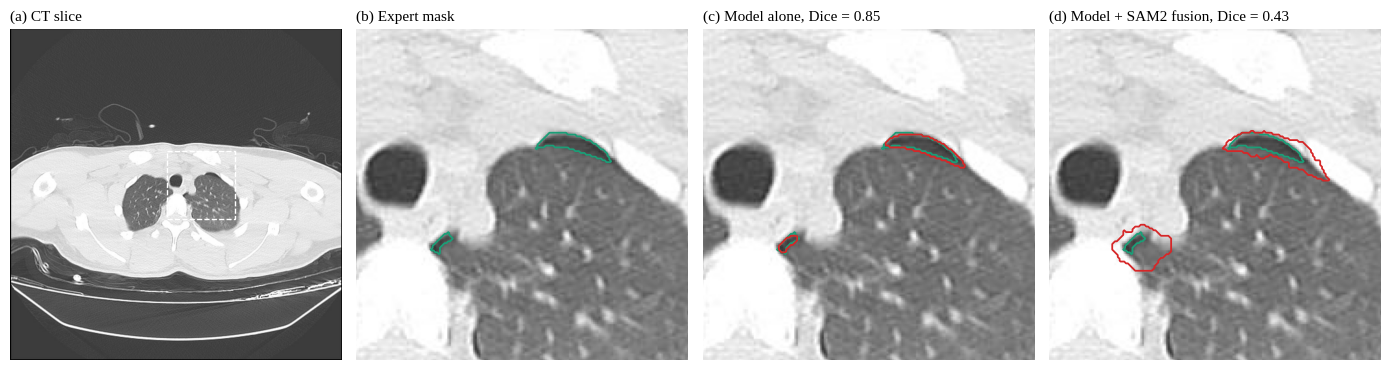

In [5]:
YESIL, KIRMIZI = '#1B9E77', '#D62728'


def kontur(ax, m, renk, lw=1.3):
    if m.sum() > 0:
        ax.contour(m.astype(float), levels=[0.5], colors=[renk], linewidths=lw)


def kirp(ax, maskeler, img):
    ys, xs = np.where(np.any(maskeler, axis=0))
    cy, cx = int(ys.mean()), int(xs.mean()); r = max(90, int(max(np.ptp(ys), np.ptp(xs)) * 0.7))
    ax.set_xlim(max(cx - r, 0), min(cx + r, img.shape[1])); ax.set_ylim(min(cy + r, img.shape[0]), max(cy - r, 0))
    return cx, cy, r


dm = np.array([po.segmentation_metrics(m, g)['dice'] for m, g in zip(tek, GT)])
df_ = np.array([po.segmentation_metrics(m, g)['dice'] for m, g in zip(bir, GT)])
aday = np.where(dm >= 0.8)[0]
i = int(aday[np.argmin(df_[aday] - dm[aday])])
print(f'Secilen kesit sirasi {i}: model Dice {dm[i]:.3f}, birlesim Dice {df_[i]:.3f}, aday sayisi {len(aday)}')
print(f'Model >= 0,8 olan kesitlerde birlesim Dice kaybi: medyan {np.median(dm[aday] - df_[aday]):.3f}, '
      f'kayip > 0,1 olan {int(((dm[aday] - df_[aday]) > 0.1).sum())} kesit')
im, g, m0, m1 = IMG[i], GT[i], tek[i], bir[i]
fig, ax = plt.subplots(1, 4, figsize=(14, 3.9))
for a in ax:
    a.imshow(im); a.axis('off')
cx, cy, r = kirp(ax[1], np.stack([g, m0, m1]), im)
for a in ax[2:]:
    a.set_xlim(ax[1].get_xlim()); a.set_ylim(ax[1].get_ylim())
ax[0].add_patch(plt.Rectangle((cx - r, cy - r), 2 * r, 2 * r, fill=False, ec='white', lw=1, ls='--'))
kontur(ax[1], g, YESIL)
kontur(ax[2], g, YESIL); kontur(ax[2], m0, KIRMIZI)
kontur(ax[3], g, YESIL); kontur(ax[3], m1, KIRMIZI)
for a, t in zip(ax, ['(a) CT slice', '(b) Expert mask', f'(c) Model alone, Dice = {dm[i]:.2f}', f'(d) Model + SAM2 fusion, Dice = {df_[i]:.2f}']):
    a.set_title(t, fontsize=11, loc='left')
plt.tight_layout()
for uz in ('png', 'pdf'):
    plt.savefig(f'{OUT_DIR}/Figure4_sam2_leakage.{uz}', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

## 3. Sekil 6: ek1'de secilen basarisiz kesitler (yalniz isaretleme, model maskesi)

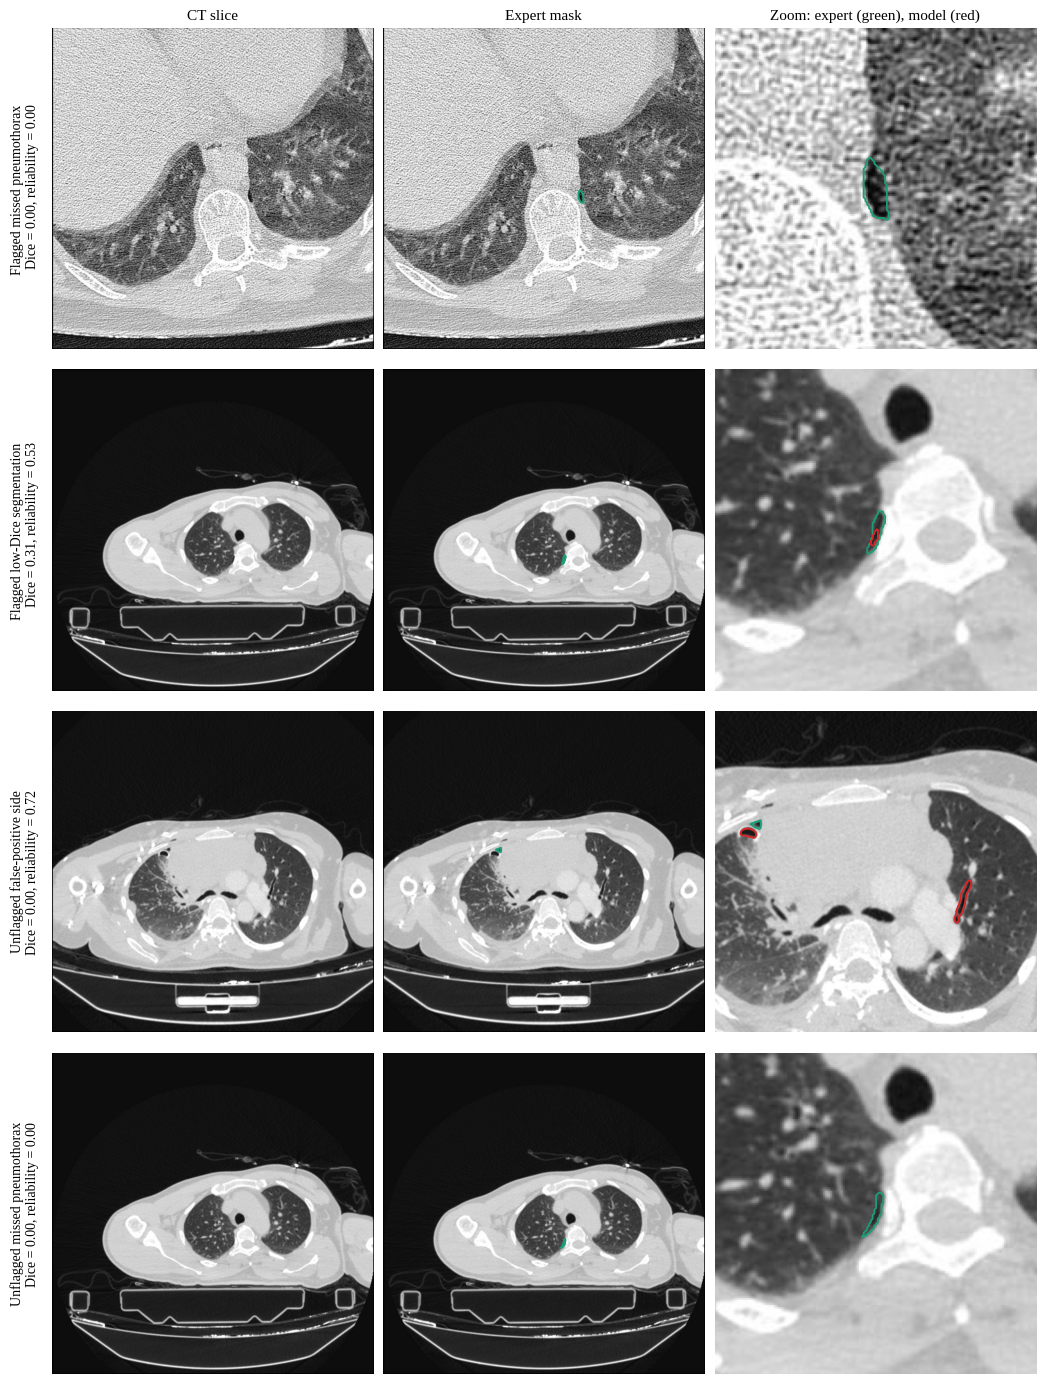

Bitti. Ciktilar: /content/drive/MyDrive/pnx_ek_analizler


In [6]:
S = pd.read_csv(SECIM_CSV, dtype={'patient_id': str})
konum = {(p, s): k for k, (p, s, _, _) in enumerate(TEST)}
n = len(S)
fig, ax = plt.subplots(n, 3, figsize=(10.5, 3.5 * n))
ax = np.atleast_2d(ax)
for r, s in enumerate(S.itertuples()):
    k = konum[(s.patient_id, s.slice)]
    im, g, m = IMG[k], GT[k], tek[k]
    for j in range(3):
        ax[r, j].imshow(im); ax[r, j].axis('off')
    kontur(ax[r, 1], g, YESIL); kontur(ax[r, 2], g, YESIL); kontur(ax[r, 2], m, KIRMIZI)
    kirp(ax[r, 2], np.stack([g, m]), im)
    ax[r, 0].text(-0.04, 0.5, f'{s.en}' + chr(10) + f'Dice = {s.dice:.2f}, reliability = {s.guvenilirlik:.2f}',
                  transform=ax[r, 0].transAxes, rotation=90, ha='right', va='center', fontsize=10)
for j, t in enumerate(('CT slice', 'Expert mask', 'Zoom: expert (green), model (red)')):
    ax[0, j].set_title(t, fontsize=11)
plt.tight_layout()
for uz in ('png', 'pdf'):
    plt.savefig(f'{OUT_DIR}/Figure_failure_examples.{uz}', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
print('Bitti. Ciktilar:', OUT_DIR)